# Customer Churn Prediction using Logistic Regression

**Course:** CSE3141 — Predictive Analytics
**Project Type:** Mini Project

## 1. Project Introduction

This notebook builds a machine learning model that predicts whether a telecom
customer is likely to **churn** (cancel their subscription) using
**Logistic Regression**.

The notebook is organized in stages that are built up incrementally:

1. Problem Definition (this stage)
2. Data Cleaning
3. Exploratory Data Analysis (EDA)
4. Logistic Regression Training
5. Model Validation and Hyperparameter Tuning

Each stage only contains the work relevant to that stage. Data loading,
cleaning, visualizations, and modeling are implemented in later stages so
that every number reported is based on the real dataset, never invented.

## 2. What is Customer Churn, and Why Does It Matter?

**Customer churn** means a customer stops using a company's service —
for example, a telecom subscriber cancelling their plan and switching to a
competitor.

### Why telecom companies care about churn

- Acquiring a brand-new customer is significantly more expensive (through
  advertising, promotional offers, and onboarding) than keeping an existing
  one.
- Even a small reduction in churn rate can have a large effect on long-term
  revenue, because the customer keeps paying every month instead of leaving.
- If a company can predict *in advance* which customers are at risk of
  leaving, it can take action early — for example, offering a loyalty
  discount, improving a specific service, or reaching out proactively —
  **before** the customer actually cancels.

This is exactly why churn prediction is a classic, high-value use case for
predictive analytics in the telecom industry.

## 3. Objectives and Expected Outcomes

### Business Objective
Identify which customers are at high risk of churning so the business can
prioritize retention efforts (offers, support outreach, service
improvements) towards those customers specifically, instead of treating
every customer the same way.

### Machine Learning Objective
Build a **binary classification** model that takes a customer's account
and service details as input and outputs:

- A **predicted class**: will the customer churn (`Yes`) or not (`No`)?
- A **churn probability**: a number between 0 and 1 representing how likely
  the model thinks that customer is to churn.

### Expected Outcome
A trained Logistic Regression model, evaluated using standard classification
metrics (accuracy, precision, recall, F1-score, ROC-AUC — all defined and
computed in Stage 5), along with an interactive demo app where a user can
enter a hypothetical customer's details and see the predicted churn risk.

No specific accuracy or performance number is claimed at this stage — those
will be reported honestly in Stage 5 once the model is actually trained and
evaluated on real data.

## 4. Dataset Description

This project uses the **Telco Customer Churn** dataset, a well-known public
dataset (originally published by IBM, widely distributed via Kaggle) used in
churn-modeling tutorials and research.

- **File:** `WA_Fn-UseC_-Telco-Customer-Churn.csv`
- **Rows:** 7,043 customers
- **Columns:** 21 (20 input/descriptive columns + 1 target column)

### All 21 Original Columns

| # | Column | Description |
|---|--------|--------------|
| 1 | `customerID` | Unique identifier for each customer (not predictive — dropped during cleaning) |
| 2 | `gender` | Customer's gender (`Male`/`Female`) — kept for descriptive analysis only, see Ethics section |
| 3 | `SeniorCitizen` | Whether the customer is a senior citizen (1) or not (0) |
| 4 | `Partner` | Whether the customer has a partner (`Yes`/`No`) |
| 5 | `Dependents` | Whether the customer has dependents (`Yes`/`No`) |
| 6 | `tenure` | Number of months the customer has stayed with the company |
| 7 | `PhoneService` | Whether the customer has phone service (`Yes`/`No`) |
| 8 | `MultipleLines` | Whether the customer has multiple phone lines (`Yes`/`No`/`No phone service`) |
| 9 | `InternetService` | Type of internet service (`DSL`/`Fiber optic`/`No`) |
| 10 | `OnlineSecurity` | Whether the customer has online security add-on (`Yes`/`No`/`No internet service`) |
| 11 | `OnlineBackup` | Whether the customer has online backup add-on (`Yes`/`No`/`No internet service`) |
| 12 | `DeviceProtection` | Whether the customer has device protection add-on (`Yes`/`No`/`No internet service`) |
| 13 | `TechSupport` | Whether the customer has tech support add-on (`Yes`/`No`/`No internet service`) |
| 14 | `StreamingTV` | Whether the customer has streaming TV (`Yes`/`No`/`No internet service`) |
| 15 | `StreamingMovies` | Whether the customer has streaming movies (`Yes`/`No`/`No internet service`) |
| 16 | `Contract` | Contract term (`Month-to-month`/`One year`/`Two year`) |
| 17 | `PaperlessBilling` | Whether the customer uses paperless billing (`Yes`/`No`) |
| 18 | `PaymentMethod` | How the customer pays (`Electronic check`/`Mailed check`/`Bank transfer (automatic)`/`Credit card (automatic)`) |
| 19 | `MonthlyCharges` | Current monthly charge amount (numeric) |
| 20 | `TotalCharges` | Total amount charged to the customer over their tenure (numeric, stored as text in the raw file) |
| 21 | `Churn` | **Target variable** — whether the customer churned (`Yes`/`No`) |

A detailed inspection of actual row counts, data types, and missing values
is performed in Stage 2 (Data Cleaning), where the real numbers from the
dataset are reported rather than assumed here.

## 5. Input Features vs. Target Variable

In a supervised machine learning problem, every row is split conceptually
into:

- **Input features (X):** the columns the model is allowed to look at to
  make a prediction. Here, that is all columns *except* `customerID` (just
  an identifier, not predictive) and `Churn` (the thing we are trying to
  predict).
- **Target variable (y):** the column we want the model to predict. Here,
  that is `Churn`, which takes the value `Yes` or `No`. Because there are
  exactly two possible outcomes, this is a **binary classification**
  problem.

During preprocessing (Stage 2), categorical input features (like
`Contract` or `PaymentMethod`) are converted into a numeric form the model
can use, and numeric features (like `MonthlyCharges`) are scaled — but the
*conceptual* split between "inputs" and "target" is decided here, in the
problem definition.

## 6. Ethical Considerations

Machine learning models can unintentionally encode unfair bias if they are
trained on sensitive attributes. This dataset includes `gender`, which is
useful for *descriptive* analysis (for example, checking whether churn rate
differs noticeably between groups), but:

> **Gender must not be used as an input feature for the predictive model or
> for any customer retention decision.**

**Why this matters:**

- Using gender to decide who receives a retention offer (or who is denied
  one) would be a form of discriminatory decision-making, regardless of
  whether the model's statistical performance improves.
- A good churn-prediction system should base its decisions on
  *behavior and account attributes* (tenure, contract type, charges,
  services used) — not on demographic attributes a customer cannot control
  and that have no legitimate causal link to deserving better service.

**How this is enforced in this project:** `gender` is explored in the EDA
stage purely for descriptive insight, but it is **excluded from the feature
set** used to train the Logistic Regression model in Stage 4 onward.

### Other limitations to keep in mind
- This is a single, static snapshot of customer data — it does not capture
  trends over time or events after the data was collected.
- The model reflects patterns in *this specific* telecom provider's
  customer base and may not generalize to a different company without
  retraining.

## 7. Why Logistic Regression for This Problem?

**Logistic Regression** is a statistical model used for **binary
classification** — predicting one of two possible outcomes (here, `Churn`
= `Yes` or `No`).

It is a strong first choice for this problem for several reasons:

1. **Matches the problem type.** Logistic Regression is specifically
   designed to model the probability of a binary outcome, using the
   **sigmoid function** to squeeze any numeric input into a value between
   0 and 1 — which is exactly the "churn probability" this project needs to
   produce.
2. **Interpretability.** Each input feature gets a **coefficient**. The
   sign and size of a coefficient directly show whether that feature
   increases or decreases churn risk, and by how much (via **odds
   ratios**, covered in Stage 4). This matters for a business: it's not
   enough to know *who* will churn, decision-makers also want to know
   *why*, so they can act on it.
3. **Good baseline for tabular data.** With a mix of categorical and
   numeric features like this dataset has, Logistic Regression is a
   well-understood, fast-to-train baseline that is standard practice before
   trying more complex models.
4. **Handles class imbalance with simple tools.** The dataset has more
   non-churners than churners (confirmed with real counts in Stage 2).
   Logistic Regression supports a `class_weight="balanced"` setting (used
   in Stage 4) that adjusts for this imbalance without needing to modify
   the dataset itself.

This project also trains a **Linear Discriminant Analysis (LDA)** model in
Stage 5 purely as a comparison baseline, to check whether Logistic
Regression's performance is actually competitive on this dataset.

In [1]:
# ---------------------------------------------------------------
# Initial setup: import the libraries used throughout this notebook.
# No dataset is loaded here — loading and cleaning the data is the
# subject of Stage 2 (Data Cleaning), kept in a separate section so
# each stage stays focused on one part of the project.
# ---------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split

# Display settings: show all columns when printing a DataFrame
pd.set_option("display.max_columns", None)

print("Setup complete. Libraries imported successfully.")

Setup complete. Libraries imported successfully.


## 8. Stage 2 — Data Cleaning and Preprocessing

This section loads the real dataset, inspects it, and cleans it using the
reusable functions defined in `src/preprocess.py`. No statistics in this
section are invented — every number below is the actual output of running
these cells against `data/WA_Fn-UseC_-Telco-Customer-Churn.csv`.

In [2]:
import sys
sys.path.insert(0, "..")

from src.preprocess import (
    load_data,
    inspect_data,
    remove_duplicates,
    convert_total_charges,
    handle_missing_total_charges,
    drop_customer_id,
    detect_outliers_iqr,
    plot_boxplots,
    identify_feature_types,
    build_preprocessing_pipeline,
)

DATA_PATH = "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"

raw_df = load_data(DATA_PATH)
raw_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 8.1 Initial Inspection

`inspect_data()` reports the dataset's shape, column data types, missing
values, duplicate rows, and the Churn distribution — all computed directly
from the loaded CSV.

In [3]:
summary = inspect_data(raw_df)

print("Rows:", summary["n_rows"])
print("Columns:", summary["n_columns"])
print()
print("Data types:")
for col, dtype in summary["dtypes"].items():
    print(f"  {col}: {dtype}")
print()
print("Missing values (NaN) per column:")
print({k: v for k, v in summary["missing_per_column"].items() if v > 0} or "None")
print()
print("Duplicate rows:", summary["duplicate_rows"])
print()
print("Churn distribution:", summary["churn_counts"])

Rows: 7043
Columns: 21

Data types:
  customerID: object
  gender: object
  SeniorCitizen: int64
  Partner: object
  Dependents: object
  tenure: int64
  PhoneService: object
  MultipleLines: object
  InternetService: object
  OnlineSecurity: object
  OnlineBackup: object
  DeviceProtection: object
  TechSupport: object
  StreamingTV: object
  StreamingMovies: object
  Contract: object
  PaperlessBilling: object
  PaymentMethod: object
  MonthlyCharges: float64
  TotalCharges: object
  Churn: object

Missing values (NaN) per column:
None

Duplicate rows: 0

Churn distribution: {'No': 5174, 'Yes': 1869}


**Insight:** The dataset has 7,043 rows and 21 columns, no fully
duplicate rows, and no `NaN` values reported by pandas directly — but as
the next step shows, `TotalCharges` hides 11 blank-string values that
`isnull()` does not catch because they are not technically `NaN` until
converted to numeric. The target `Churn` is imbalanced: far more customers
did **not** churn (`No`) than did (`Yes`), which is why
`class_weight="balanced"` will matter later in Stage 4.

### 8.2 Duplicate Records

`remove_duplicates()` drops any fully duplicate rows (every column
identical). Since the inspection above already reported 0 duplicate rows,
this step changes nothing for this dataset, but it is still included as a
defensive, reusable cleaning step.

In [4]:
deduped_df = remove_duplicates(raw_df)
print("Shape before:", raw_df.shape, "| Shape after:", deduped_df.shape)

Shape before: (7043, 21) | Shape after: (7043, 21)


### 8.3 Converting TotalCharges to Numeric

`TotalCharges` is stored as **text** in the raw CSV (note the `object`
dtype above), even though it is a monetary amount. `convert_total_charges()`
uses `pd.to_numeric(..., errors="coerce")`, which turns any value that
cannot be parsed as a number (the 11 blank strings) into `NaN`, making them
explicit and detectable instead of silently hiding inside a text column.

In [5]:
converted_df = convert_total_charges(deduped_df)
n_missing = converted_df["TotalCharges"].isnull().sum()
print("TotalCharges dtype after conversion:", converted_df["TotalCharges"].dtype)
print("Missing TotalCharges values after conversion:", n_missing)

TotalCharges dtype after conversion: float64
Missing TotalCharges values after conversion: 11


### 8.4 Investigating and Handling the Missing TotalCharges Values

Before blindly filling the 11 missing values, we inspect *who* they belong
to.

In [6]:
missing_rows = converted_df[converted_df["TotalCharges"].isnull()]
missing_rows[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


**Finding:** All 11 rows with a missing `TotalCharges` have
`tenure == 0` — these are brand-new customers who have not yet completed a
single billing cycle. A `TotalCharges` of 0 is therefore the logically
correct value for them, not a guess. `handle_missing_total_charges()`
verifies this condition (tenure == 0 for every missing row) before filling,
and would raise an error instead of filling if any missing row had
non-zero tenure — so this fill is never applied blindly.

In [7]:
cleaned_df = handle_missing_total_charges(converted_df)
print("Missing TotalCharges values after filling:", cleaned_df["TotalCharges"].isnull().sum())
cleaned_df.loc[missing_rows.index, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Missing TotalCharges values after filling: 0


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,0.0,No
753,0,20.25,0.0,No
936,0,80.85,0.0,No
1082,0,25.75,0.0,No
1340,0,56.05,0.0,No
3331,0,19.85,0.0,No
3826,0,25.35,0.0,No
4380,0,20.00,0.0,No
5218,0,19.70,0.0,No
6670,0,73.35,0.0,No


### 8.5 Removing customerID

`customerID` uniquely identifies each row and has no relationship with
whether a customer churns — keeping it as a feature would just add noise
(or let the model "memorize" training rows instead of learning general
patterns). `drop_customer_id()` removes it.

In [8]:
cleaned_df = drop_customer_id(cleaned_df)
print("Columns after dropping customerID:", cleaned_df.shape[1])
print("'customerID' in columns:", "customerID" in cleaned_df.columns)

Columns after dropping customerID: 20
'customerID' in columns: False


### 8.6 Outlier Investigation Using the IQR Method

The **IQR (Interquartile Range)** method flags a value as a statistical
outlier if it falls more than 1.5×IQR below the 25th percentile (Q1) or
above the 75th percentile (Q3). This is computed — not assumed — for each
numeric column below, and outliers are only **reported**, never
automatically removed, since an "outlier" here (e.g. a customer with very
high tenure) can be a perfectly real, valid customer rather than a data
error.

In [9]:
numeric_cols_to_check = ["tenure", "MonthlyCharges", "TotalCharges"]
outlier_report = detect_outliers_iqr(cleaned_df, numeric_cols_to_check)

for col, stats in outlier_report.items():
    print(f"--- {col} ---")
    print(f"  Q1={stats['Q1']:.2f}, Q3={stats['Q3']:.2f}, IQR={stats['IQR']:.2f}")
    print(f"  Bounds: [{stats['lower_bound']:.2f}, {stats['upper_bound']:.2f}]")
    print(f"  Outliers found: {stats['outlier_count']}")

--- tenure ---
  Q1=9.00, Q3=55.00, IQR=46.00
  Bounds: [-60.00, 124.00]
  Outliers found: 0
--- MonthlyCharges ---
  Q1=35.50, Q3=89.85, IQR=54.35
  Bounds: [-46.02, 171.38]
  Outliers found: 0
--- TotalCharges ---
  Q1=398.55, Q3=3786.60, IQR=3388.05
  Bounds: [-4683.52, 8868.67]
  Outliers found: 0


**Insight:** None of the three numeric columns (`tenure`,
`MonthlyCharges`, `TotalCharges`) contain any IQR outliers in this dataset
— every value falls within the computed bounds. This is a genuine result
of running the IQR calculation on the real data, not an assumption; it
means no rows need to be removed or capped for these columns.

### 8.7 Box Plots

Box plots visualize the same Q1/Q3/IQR statistics computed above: the box
spans Q1 to Q3, the line inside is the median, and the whiskers extend to
the IQR bounds. Each plot is saved as a PNG to `reports/figures/`.

In [10]:
saved_paths = plot_boxplots(cleaned_df, numeric_cols_to_check, output_dir="../reports/figures")
print("Saved plots:")
for p in saved_paths:
    print(" -", p)

Saved plots:
 - ../reports/figures\boxplot_tenure.png
 - ../reports/figures\boxplot_MonthlyCharges.png
 - ../reports/figures\boxplot_TotalCharges.png


**Insight:** The box plots visually confirm the IQR calculation above
— no points appear beyond the whiskers for any of the three columns, which
matches the 0-outlier result found numerically.

### 8.8 Identifying Categorical and Numerical Features

`identify_feature_types()` splits the cleaned dataframe's columns into
categorical and numerical feature lists, ready for the preprocessing
pipeline. **`gender` is deliberately excluded** from both lists by
default, for the ethical reason stated in Section 6: it must not be used
as a predictive input or influence any retention decision. `Churn` (the
target) is also excluded, since it is the label, not a feature.

In [11]:
categorical_cols, numerical_cols = identify_feature_types(cleaned_df)

print("Categorical feature columns:", categorical_cols)
print()
print("Numerical feature columns:", numerical_cols)
print()
print("'gender' excluded from features:", "gender" not in categorical_cols and "gender" not in numerical_cols)

Categorical feature columns: ['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical feature columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

'gender' excluded from features: True


### 8.9 Building the Preprocessing Pipeline (Not Fitted Here)

`build_preprocessing_pipeline()` returns a scikit-learn `ColumnTransformer`
that will:

- **One-hot encode** the categorical columns — turning a column like
  `Contract` (`Month-to-month`/`One year`/`Two year`) into multiple binary
  (0/1) columns, since Logistic Regression needs numeric input and has no
  natural way to interpret category text. `handle_unknown="ignore"` means
  that if a category never seen during training appears later (e.g. a new
  `PaymentMethod`), it is encoded as all zeros instead of crashing.
- **Standard-scale** the numerical columns — transforming each one to have
  mean 0 and standard deviation 1, so that columns on very different
  scales (e.g. `tenure` in months vs. `TotalCharges` in currency) contribute
  more comparably to the model instead of the larger-magnitude column
  dominating just because of its units.

**This pipeline is intentionally left UNFITTED here.** Fitting a scaler or
encoder on the entire dataset before splitting into train/test would leak
information about the test set into training (the scaler would "see"
test-set values when computing its mean/std). The pipeline below is only
constructed now; it will be `.fit()` on the training split only in Stage 4,
then reused with `.transform()` on the test split and any new customer
data.

In [12]:
preprocessor = build_preprocessing_pipeline(categorical_cols, numerical_cols)
preprocessor

ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['Partner', 'Dependents', 'PhoneService',
                                  'MultipleLines', 'InternetService',
                                  'OnlineSecurity', 'OnlineBackup',
                                  'DeviceProtection', 'TechSupport',
                                  'StreamingTV', 'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod']),
                                ('numerical', StandardScaler(),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges'])])

**Summary of Stage 2:** the dataset has been loaded, inspected,
deduplicated (no duplicates found), had `TotalCharges` converted to a
proper numeric type with its 11 missing values filled based on verified
zero-tenure status, had the non-predictive `customerID` dropped, been
checked for outliers (none found) with box plots saved for the report, and
had its features split into categorical/numerical lists with `gender`
excluded. An unfitted preprocessing pipeline is ready to be fitted on the
training data in Stage 4.

## 9. Exploratory Data Analysis

This section visualizes the cleaned dataset to understand *what* patterns
exist before building a predictive model in Stage 4. Every chart below is
generated directly from `data/WA_Fn-UseC_-Telco-Customer-Churn.csv` via the
`clean_dataset()` function from Stage 2 — no numbers here are invented.

`gender` is examined only if it comes up descriptively; it is never used as
a predictive feature or to drive any retention decision (see Section 6).

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from src.preprocess import clean_dataset

eda_df = clean_dataset(DATA_PATH)
eda_df["Churn_binary"] = (eda_df["Churn"] == "Yes").astype(int)
eda_df.shape

(7043, 21)

### 9.1 Key Statistics

Before charting, we compute the actual summary numbers referenced in the
interpretations below.

In [14]:
total_customers = len(eda_df)
churn_counts = eda_df["Churn"].value_counts()
churn_pct = eda_df["Churn"].value_counts(normalize=True) * 100

overall_churn_rate = churn_pct["Yes"]

avg_tenure_by_churn = eda_df.groupby("Churn")["tenure"].mean()
avg_monthly_by_churn = eda_df.groupby("Churn")["MonthlyCharges"].mean()
churn_rate_by_contract = eda_df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean() * 100)

print(f"Total customers: {total_customers}")
print(f"Churned: {churn_counts['Yes']} ({churn_pct['Yes']:.2f}%)")
print(f"Retained: {churn_counts['No']} ({churn_pct['No']:.2f}%)")
print(f"Overall churn rate: {overall_churn_rate:.2f}%")
print()
print("Average tenure (months) by churn status:")
print(avg_tenure_by_churn.round(2))
print()
print("Average MonthlyCharges by churn status:")
print(avg_monthly_by_churn.round(2))
print()
print("Churn rate (%) by contract type:")
print(churn_rate_by_contract.round(2))

Total customers: 7043
Churned: 1869 (26.54%)
Retained: 5174 (73.46%)
Overall churn rate: 26.54%

Average tenure (months) by churn status:
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

Average MonthlyCharges by churn status:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64

Churn rate (%) by contract type:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


### 9.2 Chart 1 — Overall Churn Distribution (Pie Chart)

A pie chart is a natural fit here because we are showing how a single
whole (all 7,043 customers) splits into two mutually exclusive parts
(churned vs. retained) — exactly the kind of "parts of a whole" comparison
pie charts communicate well, and with only two categories it stays easy to
read (pie charts become harder to interpret with many slices).

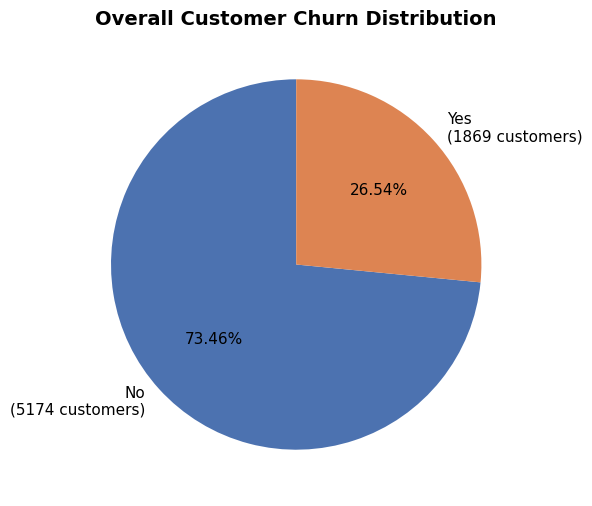

In [15]:
fig, ax = plt.subplots(figsize=(6, 6))
colors = ["#4C72B0", "#DD8452"]
ax.pie(
    churn_counts.values,
    labels=[f"{label}\n({count} customers)" for label, count in churn_counts.items()],
    autopct="%1.2f%%",
    colors=colors,
    startangle=90,
    textprops={"fontsize": 11},
)
ax.set_title("Overall Customer Churn Distribution", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig("../reports/figures/churn_distribution_pie.png", dpi=300)
plt.show()

**Interpretation:** Of 7,043 customers, 1869 churned (26.54%) and 5174 were retained (73.46%). The dataset is noticeably imbalanced toward retained customers — this is exactly why Stage 4 uses `class_weight="balanced"` when training Logistic Regression, so the model does not simply learn to always predict "No churn".

### 9.3 Chart 2 — Churn Rate by Contract Type (Bar Chart)

A bar chart is well suited for comparing a rate across a small number of
named categories. Critically, this chart plots the **percentage of
customers who churned within each contract type** (not raw counts), so
that contract types with different customer counts can be compared fairly
on equal footing.

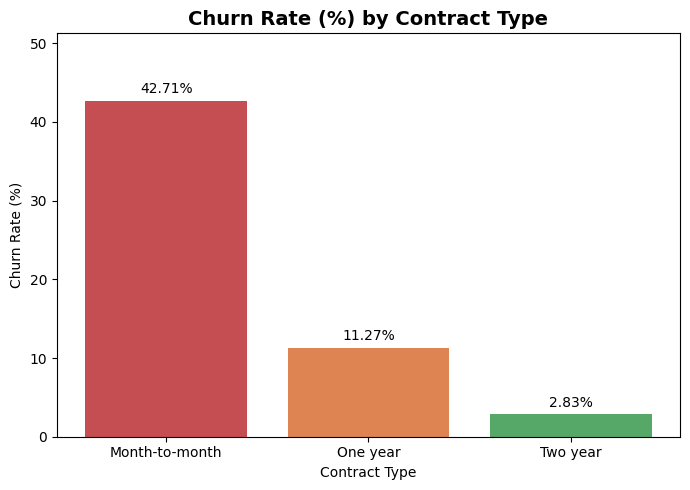

In [16]:
contract_order = ["Month-to-month", "One year", "Two year"]
churn_rate_ordered = churn_rate_by_contract.reindex(contract_order)

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(churn_rate_ordered.index, churn_rate_ordered.values, color=["#C44E52", "#DD8452", "#55A868"])
ax.set_title("Churn Rate (%) by Contract Type", fontsize=14, fontweight="bold")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, max(churn_rate_ordered.values) * 1.2)

for bar, value in zip(bars, churn_rate_ordered.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 1, f"{value:.2f}%", ha="center", fontsize=10)

fig.tight_layout()
fig.savefig("../reports/figures/churn_rate_by_contract.png", dpi=300)
plt.show()

**Interpretation:** Churn rate drops sharply as contract length
increases — Month-to-month customers churn at 42.71%, compared to
11.27% for One-year and only 2.83% for Two-year contracts.
Customers with no long-term commitment are far more likely to leave,
suggesting contract length (or whatever makes a customer choose a longer
contract, such as higher satisfaction or price lock-in) is one of the
strongest behavioral signals of churn risk in this dataset.

### 9.4 Chart 3 — Tenure Distribution (Histogram)

A histogram shows how a single numeric variable (`tenure`, in months) is
distributed across all customers by grouping values into bins and counting
how many customers fall in each bin.

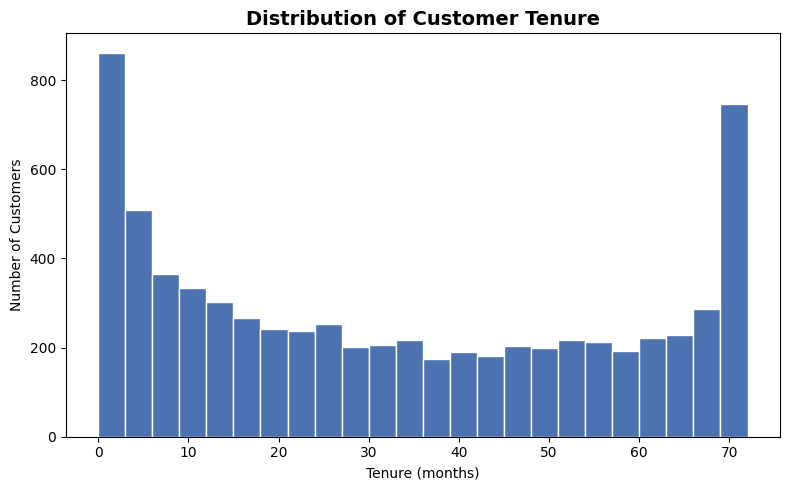

Tenure summary statistics:
count    7043.00
mean       32.37
std        24.56
min         0.00
25%         9.00
50%        29.00
75%        55.00
max        72.00
Name: tenure, dtype: float64


In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(eda_df["tenure"], bins=24, color="#4C72B0", edgecolor="white")
ax.set_title("Distribution of Customer Tenure", fontsize=14, fontweight="bold")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Number of Customers")
fig.tight_layout()
fig.savefig("../reports/figures/tenure_distribution.png", dpi=300)
plt.show()

print("Tenure summary statistics:")
print(eda_df["tenure"].describe().round(2))

**Interpretation:** Tenure ranges from 0 to 72 months with a mean of
about 32.4 months. The distribution is not a smooth bell curve — there are
noticeably large groups of customers at the very low end (near 0 months,
i.e. recently joined) and the very high end (near 72 months, i.e.
long-term loyal customers), with fewer customers in the middle. This
matches the contract-type finding above: many customers either leave early
or stay for the long haul, with fewer "in-between" cases.

### 9.5 Chart 4 — Correlation Heatmap

A **correlation heatmap** visualizes the **correlation coefficient**
between every pair of numeric columns at once, using color intensity.

- The correlation coefficient ranges from **-1 to +1**.
- A **positive correlation** (closer to +1) means as one variable
  increases, the other tends to increase too.
- A **negative correlation** (closer to -1) means as one variable
  increases, the other tends to decrease.
- A value near **0** means little to no linear relationship.

`Churn_binary` (1 = churned, 0 = retained) is included here purely to see
which numeric features move together with churn — `customerID` is
excluded (not numeric/predictive) and `gender` is excluded (ethical
requirement: never used as a predictive feature).

**Correlation does not prove causation:** two variables can correlate
strongly without one causing the other — there could be a third factor
driving both, or the relationship could be coincidental in this particular
dataset. For example, `tenure` and `TotalCharges` correlate strongly
simply because `TotalCharges` accumulates over time — it doesn't mean
tenure "causes" higher charges in a business sense, it's a direct
mathematical consequence of billing every month.

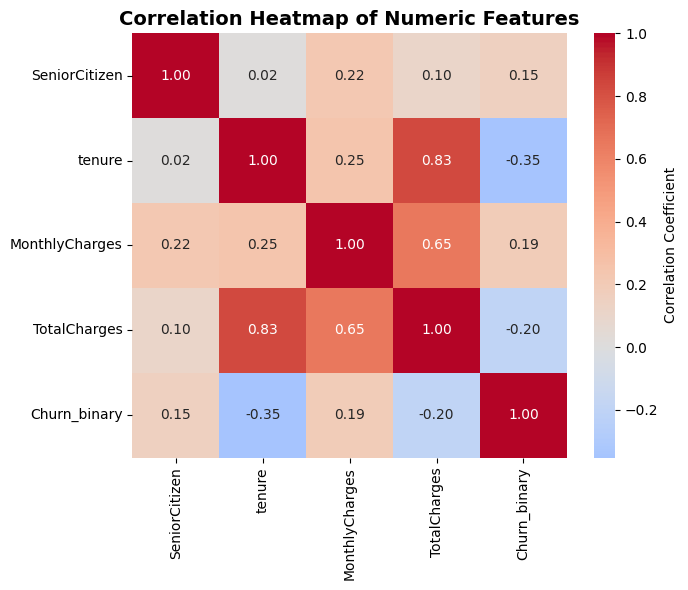

                SeniorCitizen  tenure  MonthlyCharges  TotalCharges  \
SeniorCitizen           1.000   0.017           0.220         0.103   
tenure                  0.017   1.000           0.248         0.826   
MonthlyCharges          0.220   0.248           1.000         0.651   
TotalCharges            0.103   0.826           0.651         1.000   
Churn_binary            0.151  -0.352           0.193        -0.198   

                Churn_binary  
SeniorCitizen          0.151  
tenure                -0.352  
MonthlyCharges         0.193  
TotalCharges          -0.198  
Churn_binary           1.000  


In [18]:
numeric_cols_for_corr = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "Churn_binary"]
corr_matrix = eda_df[numeric_cols_for_corr].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax,
            cbar_kws={"label": "Correlation Coefficient"})
ax.set_title("Correlation Heatmap of Numeric Features", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig("../reports/figures/correlation_heatmap.png", dpi=300)
plt.show()

print(corr_matrix.round(3))

**Interpretation:** `tenure` has the strongest relationship with churn
among these numeric features, at **-0.35** (negative) — longer-tenured
customers churn less. `MonthlyCharges` correlates **+0.19** (positive)
with churn — customers paying more per month churn somewhat more often.
`TotalCharges` correlates **-0.20** with churn, and `tenure`/`TotalCharges`
correlate strongly with each other at **+0.83**, which is expected since
`TotalCharges` is built from billing a customer every month of their
tenure — a mechanical relationship, not evidence that one factor
"causes" the other in a business sense.

### 9.6 Summary of Stage 3 Findings

- Overall churn rate: **26.54%** (1,869 of 7,043 customers).
- Churn is heavily concentrated in **Month-to-month** contracts
  (**42.71%** churn rate) versus One-year (**11.27%**) and Two-year
  (**2.83%**).
- Churned customers have a much lower average tenure (**~18.0 months**)
  than retained customers (**~37.6 months**).
- Churned customers pay a *higher* average monthly charge (**~$74.44**)
  than retained customers (**~$61.27**).
- `tenure` is the numeric feature most correlated with churn (**-0.35**),
  followed by `MonthlyCharges` (**+0.19**).

All of these numbers come directly from the cells above — no figure in
this summary was decided in advance.